# 06 — Backtest multi-pata con costos y walk-forward

**Dueño:** Juan Manuel Espinosa (JME) · **Revisor:** Gonzalo Cano (GC) · **Guía:** `docs/instrucciones/06_backtest.md`

**Objetivo.** Simular la estrategia día a día con contabilidad exacta por pata, comisión por pata, préstamo sobre los
cortos y evaluación walk-forward (entrenamiento → prueba → validación) con los parámetros congelados desde train.
Grupo: **GLD-GDX-B** (iteración 2 de la selección; la iteración 1, GLD-GDX-AEM-FNV, está al final como referencia).

> Este notebook solo **muestra**: la lógica vive en `backtest/` (motor, costos, walk-forward) y `strategy/sizing.py`;
> `python main.py` corre lo mismo y escribe `equity_curve.parquet`, `trades.csv` y `rebalance_comparison.csv`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from backtest.costs import BORROW_RATE_ANNUAL, COMMISSION, TRADING_DAYS
from backtest.engine import DEFAULT_PARAMS, run_backtest
from backtest.walk_forward import run_walk_forward, split_summary
from data.split import load_split_dates
from main import ARTIFACTS, FIGURES

pd.set_option("display.width", 160)
prices = pd.read_parquet(ARTIFACTS / "prices.parquet").drop(columns="split")
signals = pd.read_parquet(ARTIFACTS / "signals.parquet")
equity = pd.read_parquet(ARTIFACTS / "equity_curve.parquet")
trades = pd.read_csv(ARTIFACTS / "trades.csv", parse_dates=["entry_date", "exit_date"])
rebalance = pd.read_csv(ARTIFACTS / "rebalance_comparison.csv")
strategy = json.loads((ARTIFACTS / "params.json").read_text())["strategy"]
dates = load_split_dates(ARTIFACTS / "split_dates.json")
print(f"Señales: {signals.index[0].date()} → {signals.index[-1].date()} ({len(signals)} días, después de ambos burn-in)")

Señales: 2013-04-08 → 2026-10-30 (3414 días, después de ambos burn-in)


## 1. Cómo funciona el motor

Cada día t, con precios de cierre P_t:

1. **Valuación:** P&L bruto_t = Σ_i q_i (P_{i,t} − P_{i,t−1}) con las acciones que se traían de t − 1.
2. **Préstamo:** (0.25 % / 252) × nocional de las patas cortas mantenidas de t − 1 a t.
3. **Ejecución al cierre de t de la señal decidida al cierre de t − 1** (evita el look-ahead de operar al mismo
   cierre que generó la señal). Acciones objetivo con el sizing de clase:
   N_i = 0.8 · V_t · |β̂_i| / Σ|β̂_j|, q_i = d · sgn(β̂_i) · N_i / P_i, con V_t el capital actual.
4. **Comisión** de 0.125 % sobre lo operado **en cada pata** (entrada, salida y rebalanceos).
5. **Identidad contable:** equity_t = cash_t + Σ_i q_i P_{i,t} y ΔV_t = bruto − comisión − préstamo.

Mientras la posición sigue abierta se **rebalancea** hacia el objetivo (cambian β̂_t y V_t): cada día con
`rebalance_band = 0`, o solo las patas que se alejan más de la banda.

In [2]:
print("Parámetros del motor:", DEFAULT_PARAMS)
print(f"Comisión {COMMISSION:.3%} por pata; préstamo {BORROW_RATE_ANNUAL:.2%} anual, base {TRADING_DAYS} días")
print("Regla θ congelada desde train (parte 05):",
      {k: strategy[k] for k in ("z_entry", "z_exit", "z_stop", "max_holding")})

Parámetros del motor: {'initial_capital': 1000000.0, 'position_fraction': 0.8, 'commission': 0.00125, 'borrow_rate': 0.0025, 'trading_days': 252, 'execution_lag': 1, 'rebalance_band': 0.0}
Comisión 0.125% por pata; préstamo 0.25% anual, base 252 días
Regla θ congelada desde train (parte 05): {'z_entry': 1.0, 'z_exit': 0.0, 'z_stop': 2.5, 'max_holding': 87}


### Caso de juguete calculado a mano (el mismo de `tests/test_accounting.py`)

Dos patas con β = (1, −1). La señal +1 del cierre del día 0 se ejecuta el día 1 (400,000 largo en A y 400,000 corto
en B, comisión 0.125 % × 800,000 = 1,000); la señal 0 del día 1 cierra el día 2.

In [3]:
index = pd.bdate_range("2024-01-01", periods=4)
toy_prices = pd.DataFrame({"A": [100.0, 110.0, 120.0, 120.0], "B": [50.0, 50.0, 40.0, 40.0]}, index=index)
toy_signals = pd.DataFrame({"signal": [1, 0, 0, 0], "beta_A": 1.0, "beta_B": -1.0}, index=index)
toy = run_backtest(toy_prices, toy_signals)
toy.equity[["shares_A", "shares_B", "cash", "value_A", "value_B", "equity", "gross_pnl", "commission", "borrow",
            "net_pnl"]].round(2)

,shares_A,shares_B,cash,value_A,value_B,equity,gross_pnl,commission,borrow,net_pnl
2024-01-01,0.00,0.0,1000000.00,0.0,0.0,1000000.00,0.00,0.00,0.00,0.00
2024-01-02,3636.36,-8000.0,999000.00,400000.0,-400000.0,999000.00,0.00,1000.00,0.00,-1000.00
2024-01-03,0.00,0.0,1114415.01,0.0,0.0,1114415.01,116363.64,945.45,3.17,115415.01
2024-01-04,0.00,0.0,1114415.01,0.0,0.0,1114415.01,0.00,0.00,0.00,0.00


## 2. Walk-forward con θ congelado

Cada partición se simula por separado desde el primer día con señal, arranca con $1,000,000 y cierra sus posiciones al
final. Prueba y validación usan exactamente la regla, los filtros y los costos calibrados en train.

In [4]:
results = run_walk_forward(prices.loc[signals.index], signals, dates)
summary = pd.DataFrame({name: split_summary(result) for name, result in results.items()}).T
summary.style.format({"net_return": "{:+.2%}", "sharpe_net": "{:.2f}", "max_drawdown": "{:.2%}", "gross_pnl": "{:,.0f}",
                      "commission": "{:,.0f}", "borrow": "{:,.0f}", "net_pnl": "{:,.0f}", "cost_share_of_gross": "{:.0%}",
                      "traded_notional": "{:,.0f}", "win_rate": "{:.0%}", "exposure": "{:.0%}"})

,net_return,sharpe_net,max_drawdown,gross_pnl,commission,borrow,net_pnl,cost_share_of_gross,traded_notional,n_trades,win_rate,n_rebalances,exposure
train,+20.51%,0.66,-6.55%,"274,790","66,527","3,188","205,075",25%,"53,221,956",24.000000,79%,697.000000,38%
test,+8.07%,0.74,-4.48%,"105,774","23,598","1,451","80,725",24%,"18,878,298",9.000000,89%,349.000000,48%
validation,+11.21%,1.01,-3.72%,"142,123","28,619","1,428","112,076",21%,"22,895,304",11.000000,91%,353.000000,49%


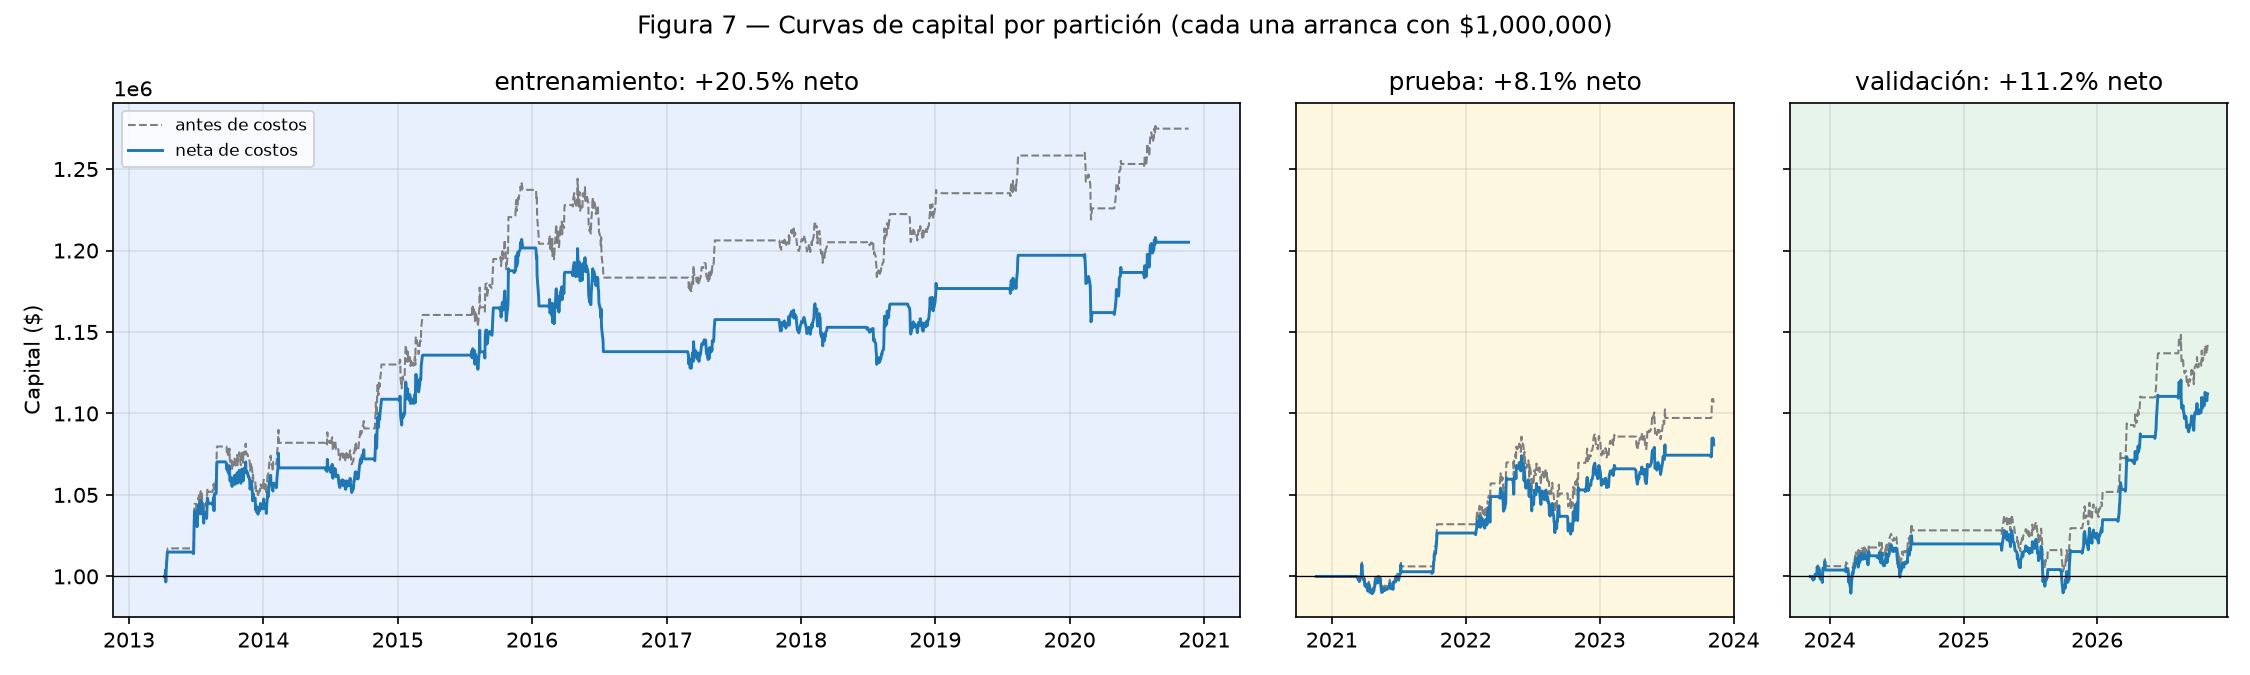

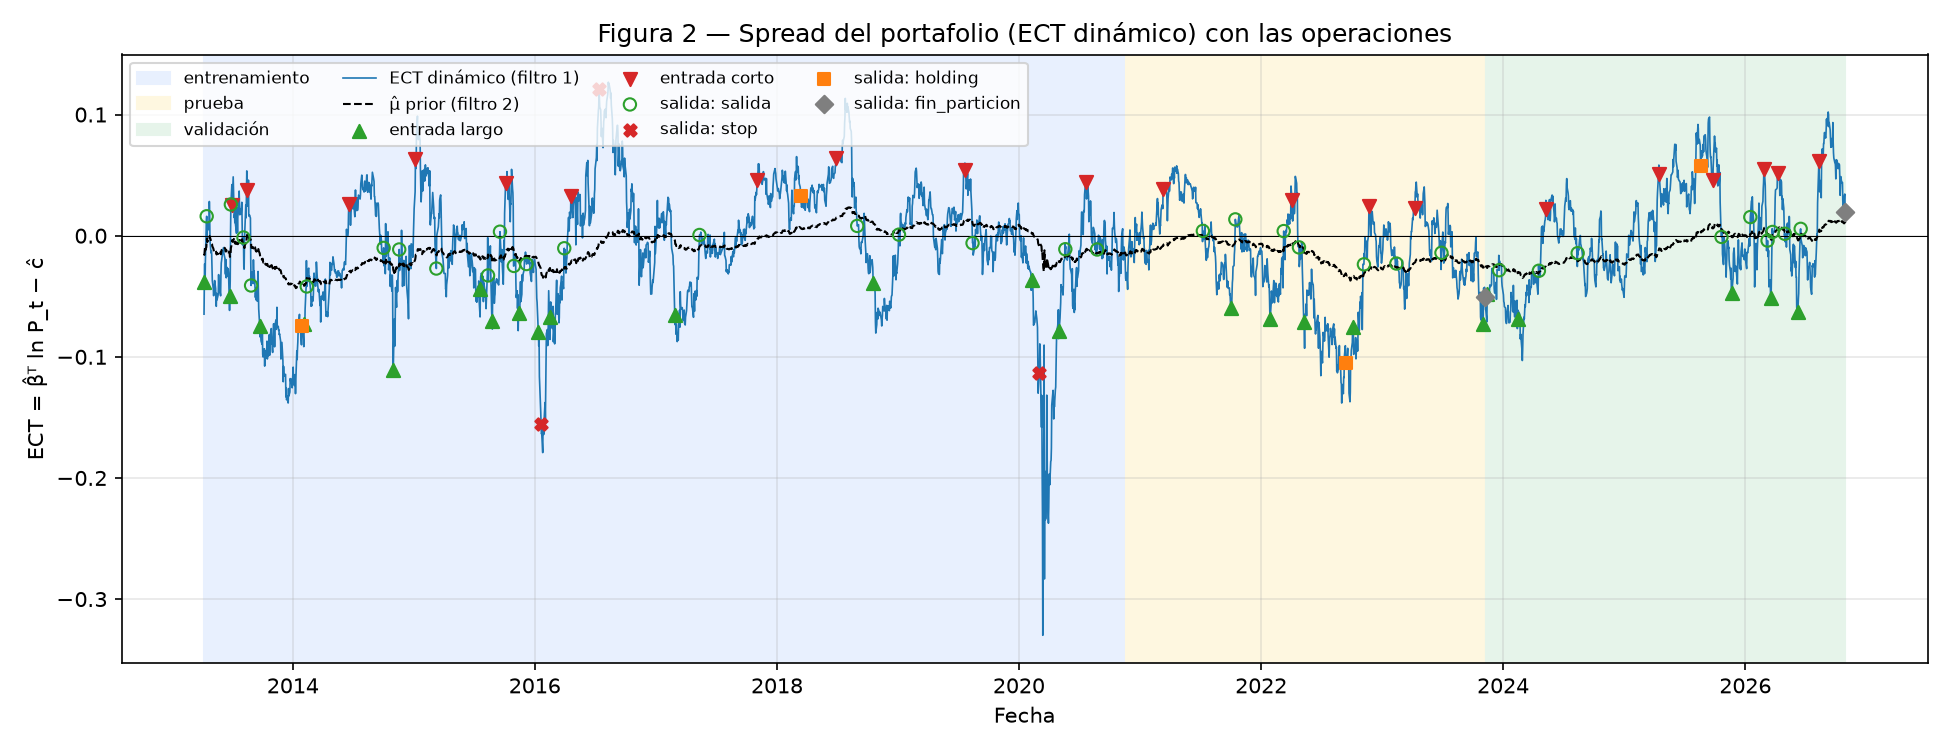

In [5]:
display(Image(filename=str(FIGURES / "fig07_curvas_capital.png")))
display(Image(filename=str(FIGURES / "fig02_spread_senales.png")))

**Lectura.**
- **Entrenamiento:** +20.5 % neto en 7.5 años, Sharpe neto 0.66, drawdown máximo −6.6 %. Es donde se eligió θ; las
  pérdidas grandes son 3 stops (dos en 2016 y uno en el desplome de marzo de 2020).
- **Prueba y validación:** +8.1 % y +11.2 % netos, Sharpe 0.74 y 1.01, drawdown −4.5 % y −3.7 %. Fuera de muestra
  no hubo ningún stop: el ECT dinámico siguió revirtiendo alrededor de su media (figura 2), que es lo que muestra el
  notebook 03 (la relación se debilita en nivel pero el filtro 1 lo absorbe).
- Fuera de muestra hay pocas operaciones (9 y 11), así que el Sharpe tiene mucho error de estimación.

## 3. Bitácora de operaciones

In [6]:
by_reason = trades.groupby(["split", "exit_reason"], sort=False)["net_pnl"].agg(operaciones="count", neto_total="sum",
                                                                          neto_promedio="mean")
by_reason.style.format({"neto_total": "{:,.0f}", "neto_promedio": "{:,.0f}"})

In [7]:
trades.sort_values("net_pnl").head(5)[["split", "entry_date", "exit_date", "direction", "days", "gross_pnl",
                                         "commission", "borrow", "net_pnl", "exit_reason"]].round({"gross_pnl": 0, "commission": 0, "borrow": 0, "net_pnl": 0})

,split,entry_date,exit_date,direction,days,gross_pnl,commission,borrow,net_pnl,exit_reason
15,train,2016-04-20,2016-07-13,-1,58,-44574.0,3892.0,241.0,-48707.0,stop
13,train,2016-01-12,2016-01-20,1,5,-33048.0,2520.0,27.0,-35594.0,stop
21,train,2020-02-10,2020-03-02,1,14,-32434.0,2659.0,74.0,-35167.0,stop
28,test,2022-05-10,2022-09-14,1,87,-19153.0,3213.0,405.0,-22771.0,holding
36,validation,2025-04-14,2025-08-19,-1,87,-12120.0,3328.0,312.0,-15760.0,holding


**Cómo pierde dinero la estrategia.** Las salidas por **salida** (reversión a la media) son las que ganan; las
pérdidas vienen de posiciones que **no revierten**: los stops de train (el spread siguió abriéndose) y las salidas
por holding máximo (87 días sin regresar). Es exactamente el riesgo de la sesión 14: una relación que deja de
revertir mientras el modelo insiste en que la reversión es inminente.

## 4. Atribución de costos: bruto = neto + comisiones + préstamo

In [8]:
attribution = equity.groupby("split", sort=False)[["gross_pnl", "commission", "borrow", "net_pnl"]].sum()
attribution["bruto − (neto + costos)"] = attribution["gross_pnl"] - (attribution["net_pnl"] + attribution["commission"]
                                                                    + attribution["borrow"])
attribution.round(2)

,gross_pnl,commission,borrow,net_pnl,bruto − (neto + costos)
split,,,,,
train,274790.05,66527.45,3187.61,205075.00,-0.0
test,105773.54,23597.87,1451.01,80724.66,0.0
validation,142123.39,28619.13,1428.38,112075.88,-0.0


Las comisiones son 24–25 % del P&L bruto en train y prueba y 21 % en validación: con 3 patas, cada operación
completa paga 6 comisiones más las de los rebalanceos. El préstamo es pequeño (0.25 % anual sobre las patas cortas).

## 5. Rebalanceo diario vs banda de no-rebalanceo

La política evaluada es el rebalanceo **diario** (con la que se eligió θ en train). La banda b solo opera una pata
cuando su nocional se aleja más de b de su objetivo.

In [9]:
cols = ["rebalance_band", "split", "net_return", "sharpe_net", "max_drawdown", "commission", "cost_share_of_gross",
        "n_rebalances", "traded_notional"]
rebalance[cols].style.format({"net_return": "{:+.2%}", "sharpe_net": "{:.2f}", "max_drawdown": "{:.2%}",
                              "commission": "{:,.0f}", "cost_share_of_gross": "{:.0%}", "traded_notional": "{:,.0f}"})

,rebalance_band,split,net_return,sharpe_net,max_drawdown,commission,cost_share_of_gross,n_rebalances,traded_notional
0,0.000000,train,+20.51%,0.66,-6.55%,"66,527",25%,697,"53,221,956"
1,0.000000,test,+8.07%,0.74,-4.48%,"23,598",24%,349,"18,878,298"
2,0.000000,validation,+11.21%,1.01,-3.72%,"28,619",21%,353,"22,895,304"
3,0.050000,train,+21.58%,0.69,-6.64%,"59,671",23%,146,"47,737,185"
4,0.050000,test,+7.94%,0.72,-4.63%,"20,484",22%,63,"16,387,181"
5,0.050000,validation,+10.99%,0.99,-4.05%,"25,350",20%,96,"20,279,874"
6,0.100000,train,+20.69%,0.66,-7.08%,"56,077",22%,45,"44,861,603"
7,0.100000,test,+9.39%,0.83,-4.45%,"19,527",18%,20,"15,621,740"
8,0.100000,validation,+11.94%,1.07,-3.38%,"24,090",18%,29,"19,271,895"
9,0.200000,train,+21.15%,0.66,-6.34%,"54,579",21%,9,"43,663,013"


**Lectura.** Rebalancear a diario cuesta: con banda de 20 % los rebalanceos bajan de 697 a 9 en train y las
comisiones bajan ≈ 18 %. En train el Sharpe casi no cambia entre bandas (0.66 diario, 0.69 con 5 %, 0.66 con 20 %), así
que train no da razón para cambiar la política; la evaluación oficial se queda con el rebalanceo diario (con el que se
eligió θ) y la banda se reporta como escenario de ahorro de costos.

## Resumen de resultados (parte 06)

| Resultado (GLD-GDX-B) | Entrenamiento | Prueba | Validación |
|---|---|---|---|
| Rendimiento neto | +20.5 % | +8.1 % | +11.2 % |
| Sharpe neto | 0.66 | 0.74 | 1.01 |
| Drawdown máximo | −6.6 % | −4.5 % | −3.7 % |
| Operaciones | 24 | 9 | 11 |
| Costos / P&L bruto | 25 % | 24 % | 21 % |

**Referencia, iteración 1 (GLD-GDX-AEM-FNV):** Sharpe neto 0.77 / 0.33 / 0.39, rendimiento +23.9 % / +2.4 % / +2.9 %;
su relación se rompió en validación (spread estático a ≈ 10 desviaciones de train en promedio, máximo ≈ 15) y solo el stop y la regla de rearme evitaron perder.

- **Contabilidad:** identidad equity = cash + Σ patas en cada día y atribución bruto = neto + costos exactas
  (`test_accounting`, prueba 3).
- **Sin look-ahead en la ejecución:** la señal del cierre de t se opera al cierre de t + 1.
- **Hallazgo:** con la tercia la estrategia mantiene el desempeño fuera de muestra porque su relación se debilita
  lentamente en lugar de romperse; las pérdidas vienen de spreads que no revierten (stops y holding).
- **Rebalanceo:** la banda reduce comisiones sin cambiar el Sharpe de train; se reporta como escenario.